In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
# Load the CSV file
df = pd.read_csv("Connections.csv")

# Display 10 random rows
sample_10 = df.sample(n=min(10, len(df)), random_state=42)
display(sample_10)

,First Name,Last Name,URL,Email Address,Company,Position,Connected On
2242,Aparnathi,Meet,https://www.linkedin.com/in/aparnathi-meet-389...,NaN,Reliance Industries Limited,Data Operator,08 Jun 2026
175,Mohmmed Furqaan,Motiwala,https://www.linkedin.com/in/mohmmed-furqaan-mo...,NaN,Gradsmart International LLP,Full Stack Engineer,19 Oct 2026
912,Harsh,Vaishnav,https://www.linkedin.com/in/harshvaishnav04,NaN,CountShield,Research Vertical Member,02 Sep 2026
1330,Roshan,gupta,https://www.linkedin.com/in/roshan-g-08196b245,NaN,Kitchen Xpress Overseas Ltd,Data Analyst,06 Aug 2026
2604,Shagul,hameed,https://www.linkedin.com/in/shagul-hameed-7375...,NaN,Sigma Specialized Inspection,Quality Inspector,26 May 2026
812,Lalit,Marathe,https://www.linkedin.com/in/lalit-marathe-9459...,NaN,NaN,NaN,05 Sep 2026
581,Umesh,Prasad,https://www.linkedin.com/in/umesh-prasad-083ba...,NaN,NaN,NaN,23 Sep 2026
2297,Sagar,Dalvi,https://www.linkedin.com/in/sagardalvi01,NaN,STEMx,AI & STEM ENGINEER,05 Jun 2026
2105,Rushang,Desai,https://www.linkedin.com/in/rushang-desai-9b7a...,NaN,NaN,NaN,15 Jun 2026
1486,Ishan,Vikash,https://www.linkedin.com/in/ishan-vikash-62a3a...,NaN,NaN,NaN,29 Jul 2026


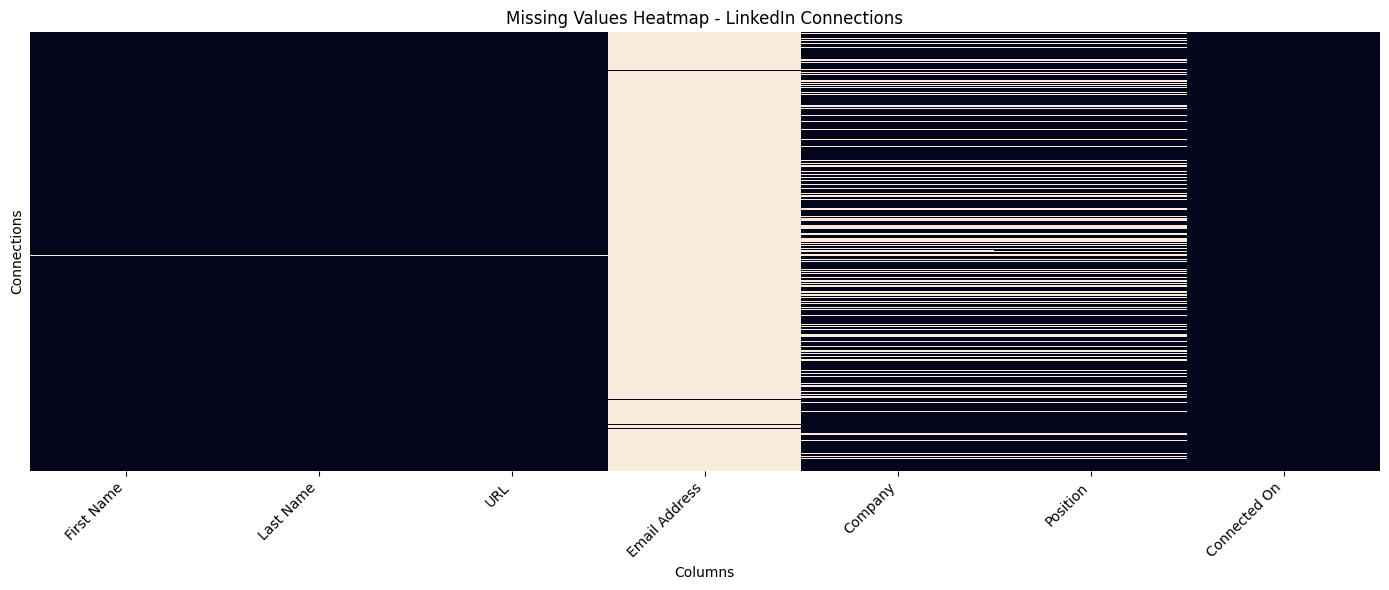

In [10]:
# Heatmap of missing values across the entire dataset
plt.figure(figsize=(14, 6))
sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    xticklabels=True
)

plt.title("Missing Values Heatmap - LinkedIn Connections")
plt.xlabel("Columns")
plt.ylabel("Connections")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [11]:
# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
First Name         17
Last Name          17
URL                17
Email Address    2585
Company           792
Position          786
Connected On        0
dtype: int64


In [12]:
# Null percentage per column
null_percentage = (df.isnull().sum() / len(df)) * 100

null_summary = pd.DataFrame({
    "Null Count": df.isnull().sum(),
    "Null Percentage (%)": null_percentage
})

null_summary = null_summary.sort_values(
    by="Null Percentage (%)",
    ascending=False
)

print(null_summary.round(2))

               Null Count  Null Percentage (%)
Email Address        2585                98.63
Company               792                30.22
Position              786                29.99
URL                    17                 0.65
Last Name              17                 0.65
First Name             17                 0.65
Connected On            0                 0.00


In [13]:
# Keep only the required columns
df = df[["First Name", "Last Name", "Connected On", "URL"]]

# Remove rows with null values in these columns
df = df.dropna(subset=["First Name", "Last Name", "Connected On", "URL"])

# Reset the index
df = df.reset_index(drop=True)

# Save the cleaned dataset
df.to_csv("cleaned_connections.csv", index=False)

print(f"Remaining connections: {len(df)}")
display(df.head())

Remaining connections: 2604


,First Name,Last Name,Connected On,URL
0,Ravi,Teja,22 Oct 2026,https://www.linkedin.com/in/ravi-teja-7a78b0195
1,Neel,Dungrani,22 Oct 2026,https://www.linkedin.com/in/neel-dungrani-0470...
2,Dev,Prajapati,22 Oct 2026,https://www.linkedin.com/in/dev-prajapati-711a...
3,Denish,Sojitra,22 Oct 2026,https://www.linkedin.com/in/denish-sojitra-472...
4,Harsh,Asleker,22 Oct 2026,https://www.linkedin.com/in/harsh-asleker-13a0...


In [1]:
import os
import time
import pandas as pd
from urllib.parse import urlparse
from ddgs import DDGS


In [2]:

INPUT_FILE = "cleaned_connections.csv"
OUTPUT_FILE = "connections_with_descriptions.csv"


In [3]:

# Read previous output when resuming, otherwise read original CSV
file_to_read = (
    OUTPUT_FILE if os.path.exists(OUTPUT_FILE)
    else INPUT_FILE
)

df = pd.read_csv(file_to_read)

# Create columns for results
for column in [
    "Profile Description",
    "Description Source URL",
    "Description Status"
]:
    if column not in df.columns:
        df[column] = ""

# Test with 10 profiles first
MAX_ROWS = 10

pending = df[
    df["Description Status"].fillna("").eq("")
]

if MAX_ROWS is not None:
    pending = pending.head(MAX_ROWS)

with DDGS() as search_engine:

    for index, row in pending.iterrows():
        first = str(row["First Name"]).strip()
        last = str(row["Last Name"]).strip()

        if not first or not last:
            df.at[index, "Description Status"] = "Missing name"
            continue

        query = (
            f'"{first} {last}" '
            f'(biography OR profile OR "about me") '
            f'-site:linkedin.com'
        )

        try:
            results = search_engine.text(
                query,
                max_results=5
            )

            found = False

            for result in results:
                title = result.get("title", "")
                snippet = result.get("body", "")
                source_url = result.get("href", "")

                domain = urlparse(source_url).netloc.lower()

                # Exclude LinkedIn itself
                if domain == "linkedin.com" or domain.endswith(".linkedin.com"):
                    continue

                # Basic name check to reduce incorrect matches
                text = f"{title} {snippet}".lower()

                if (
                    snippet
                    and first.lower() in text
                    and last.lower() in text
                ):
                    df.at[index, "Profile Description"] = snippet
                    df.at[index, "Description Source URL"] = source_url
                    df.at[index, "Description Status"] = "Snippet found"

                    found = True
                    break

            if not found:
                df.at[index, "Description Status"] = "No matching result"

        except Exception as error:
            df.at[index, "Description Status"] = (
                f"Search error: {type(error).__name__}"
            )

        # Save progress after each connection
        df.to_csv(OUTPUT_FILE, index=False)

        print(
            f"{index + 1}/{len(df)}: "
            f"{first} {last} | "
            f"{df.at[index, 'Description Status']}"
        )

        # Keep requests slow to reduce rate-limit problems
        time.sleep(3)

print("Finished. Saved to:", OUTPUT_FILE)

1/2604: Ravi Teja | No matching result
2/2604: Neel Dungrani | Search error: DDGSException
3/2604: Dev Prajapati | Snippet found
4/2604: Denish Sojitra | No matching result
5/2604: Harsh Asleker | No matching result
6/2604: Sagar Gupta | Snippet found
7/2604: Savan Vaghasiya | Search error: DDGSException


KeyboardInterrupt: 